In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_line_colors=config['cell_line_colors']

In [2]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

In [3]:
L = l2fc.copy()
L['Region'] = df.Region.copy()
L['Gene'] = df.Gene.copy()
# Ignore "Gene_Body" for now. It's mututally exclusive with "CDS" and "5'UTR" and "3'UTR"

mean_l2fc_per_gene_and_region = L.groupby(['Gene', 'Region']).mean().mean(axis=1).unstack()

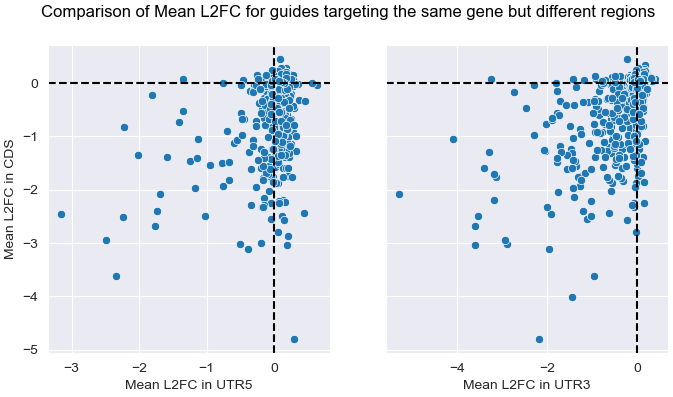

In [4]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,4), sharey=True)
for ax, key in zip(axs, ['UTR5', 'UTR3']):
    sns.scatterplot(data=mean_l2fc_per_gene_and_region, y='CDS', x=key, ax=ax)
    ax.axhline(0, color='k', linestyle='--')
    ax.axvline(0, color='k', linestyle='--')
    ax.set_xlabel(f'Mean L2FC in {key}')
    ax.set_ylabel('Mean L2FC in CDS')
pl.suptitle('Comparison of Mean L2FC for guides targeting the same gene but different regions')
pl.savefig("../results/region_specificity/l2fc_correlation_regions.pdf", bbox_inches='tight')
pl.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

essential_5'UTR vs. essential_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:4.796e-20 U_stat=7.136e+03
non-essential_5'UTR vs. non-essential_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:5.370e-01 U_stat=2.200e+02
unknown_5'UTR vs. unknown_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:2.003e-19 U_stat=4.268e+04
essential_3'UTR vs. essential_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:5.033e-09 U_stat=1.242e+04
non-essential_3'UTR vs. non-essential_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:3.020e-01 U_stat=2.970e+02
unknown_3'UTR vs. unknown_Coding
Region: Mann-Whitney-Wilcoxon test two-sided, P_val:3.580e-06 U_stat=6.278e+04


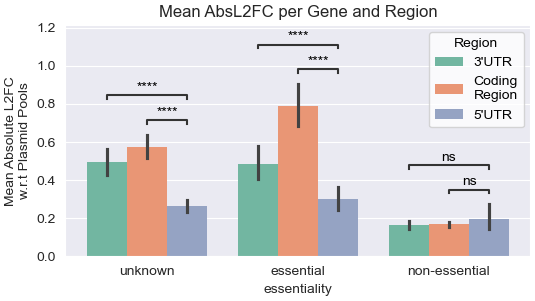

In [5]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,3))
L = np.abs(l2fc.copy())
L['Gene'] = df.Gene.copy()
L['Region'] = df['Region'].copy()
L = L[L.Region!='Gene_Body']
L.Region = L.Region.replace({'UTR5': "5'UTR", 'UTR3': "3'UTR", 'CDS': 'Coding\nRegion'})

# Annotate essentiallity based on original Bagel list
L['essentiality'] = annotate_essentiality(L.Gene)

data = L.groupby(['Gene', 'essentiality', 'Region']).mean().mean(axis=1).reset_index()
sns.barplot(data=data, x='essentiality', y=0, ax=ax, hue_order=["3'UTR", 'Coding\nRegion', "5'UTR"], hue='Region', palette='Set2')
# ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_ylabel('Mean Absolute L2FC\nw.r.t Plasmid Pools')
ax.set_title(f'Mean AbsL2FC per Gene and Region')

# Add statistical annotation
from statannotations.Annotator import Annotator
pairs=[(("unknown", "3'UTR"), ("unknown", "Coding\nRegion")),
       (("unknown", "5'UTR"), ("unknown", "Coding\nRegion")),
       (("essential", "3'UTR"), ("essential", "Coding\nRegion")),
       (("essential", "5'UTR"), ("essential", "Coding\nRegion")),
       (("non-essential", "3'UTR"), ("non-essential", "Coding\nRegion")),
       (("non-essential", "5'UTR"), ("non-essential", "Coding\nRegion")),
       ]

annotator = Annotator(ax, pairs, data=data, x='essentiality', y=0, hue='Region')
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
annotator.apply_and_annotate()

pl.savefig('../results/region_specificity/mean_abs_l2fc_per_gene_and_region_by_essentiallity.pdf', bbox_inches='tight', dpi=300)
pl.show()

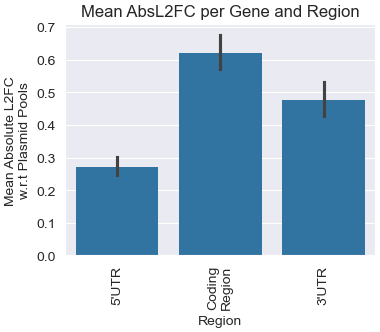

In [8]:
# Plot also without essentiallity
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,3))
data = L.groupby(['Gene', 'Region']).mean().mean(axis=1).reset_index()

sns.barplot(data=data, x='Region', y=0, ax=ax, order=["5'UTR", 'Coding\nRegion', "3'UTR"])
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_ylabel('Mean Absolute L2FC\nw.r.t Plasmid Pools')
ax.set_title(f'Mean AbsL2FC per Gene and Region')
# from statannotations.Annotator import Annotator
# pairs=[("Coding\nRegion", "3'UTR"), ("Coding\nRegion", "5'UTR")]
# annotator = Annotator(ax, pairs, data=data, x='Region', y=0, order=["5'UTR", 'Coding\nRegion', "3'UTR"])
# annotator.configure(test='t-test_ind', text_format='star', loc='inside')
# annotator.apply_and_annotate()
pl.savefig('../results/region_specificity/mean_abs_l2fc_per_gene_and_region.pdf', bbox_inches='tight', dpi=300)
pl.show()

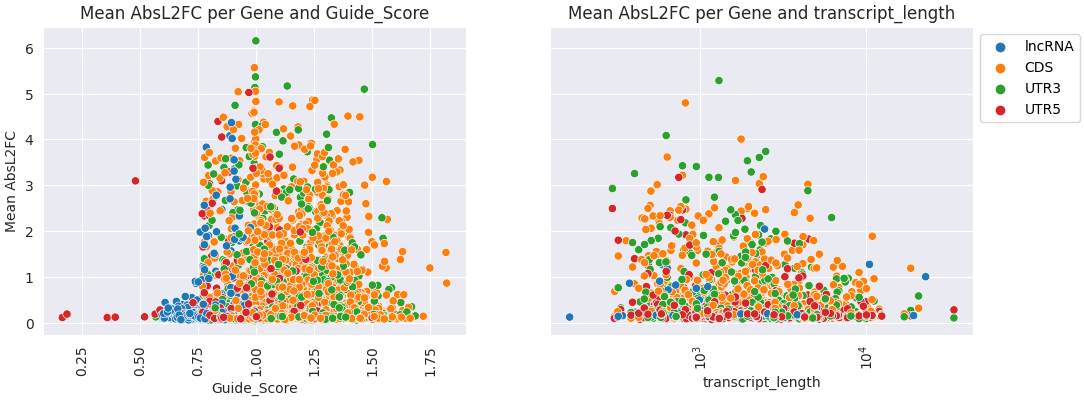

In [ ]:
keys = ['Guide_Score', 'transcript_length']
N = len(keys)
hue = 'Region'

with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, N, figsize=(6*N,4), sharey=True)

for key, ax in zip(keys, axs):
    L = np.abs(l2fc.copy())
    L['Gene'] = df.Gene.copy()
    L[key] = df[key].copy()
    L[hue] = df[hue].copy()
    if hue == 'Region':
        L[hue] = L[hue].replace({'Gene_Body': 'lncRNA'})
    data = L.groupby(['Gene', hue, key]).mean().mean(axis=1).reset_index()
    sns.scatterplot(data=data, x=key, y=0, ax=ax, hue=hue)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_ylabel('Mean AbsL2FC')
    ax.set_title(f'Mean AbsL2FC per Gene and {key}')
    if key=='transcript_length':
        ax.set_xscale('log')
    if ax==axs[1]:
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.get_legend().remove()
pl.show()


# Region specificity of guides for lncRNA?

In [ ]:
# First need location of guides in lncRNAs...